In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
from sklearn.metrics import ConfusionMatrixDisplay

In [45]:
# === User configuration ===
csv_path = "exp_lr4.7e-3_step6_gamma0.808_epochs100_cls7_ch6_win1024_stride256_bs32_wd6.7e-5_019"
list_of_experiments = ['A', 'B', 'C']
file_type = "csv"

# Label mapping
mapping = {
    'lying': 0,
    'sitting': 1,
    'standing': 2,
    'ascending stairs': 3,
    'descending stairs': 4,
    'walking': 5,
    'running': 6
}

In [46]:
# === Plotting function ===
def plot_metrics(train_pivot, val_pivot, train_metric, test_metric, train_label, test_label, y_label, title):
    plt.figure(figsize=(10, 5))
    plt.plot(train_pivot.index, train_pivot[train_metric], label=train_label, marker='o')
    plt.plot(val_pivot.index, val_pivot[test_metric], label=test_label, marker='o')
    plt.xlabel('Epoch')
    plt.ylabel(y_label)
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()


In [47]:
dfs = {}

for xp in list_of_experiments:
    df = pd.read_csv(f"{csv_path}{xp}.{file_type}")
    df['validation'] = df['validation'].astype(bool)
    
    df_train = df[df['validation'] == False]
    df_val = df[df['validation'] == True]
    
    train_pivot = df_train.pivot(index='epoch', columns='metric', values='values').astype(float)
    val_pivot = df_val.pivot(index='epoch', columns='metric', values='values')
    
    excluded_column = 'metrics.TEST_CONF'
    val_pivot.loc[:, val_pivot.columns != excluded_column] = val_pivot.loc[:, val_pivot.columns != excluded_column].astype(float)
    
    dfs[xp] = {
        "df_train": df_train,
        "df_val": df_val,
        "train_pivot": train_pivot,
        "val_pivot": val_pivot
    }

print("Data loaded and prepared for experiments:", list(dfs.keys()))


Data loaded and prepared for experiments: ['A', 'B', 'C']



=== Experiment A ===


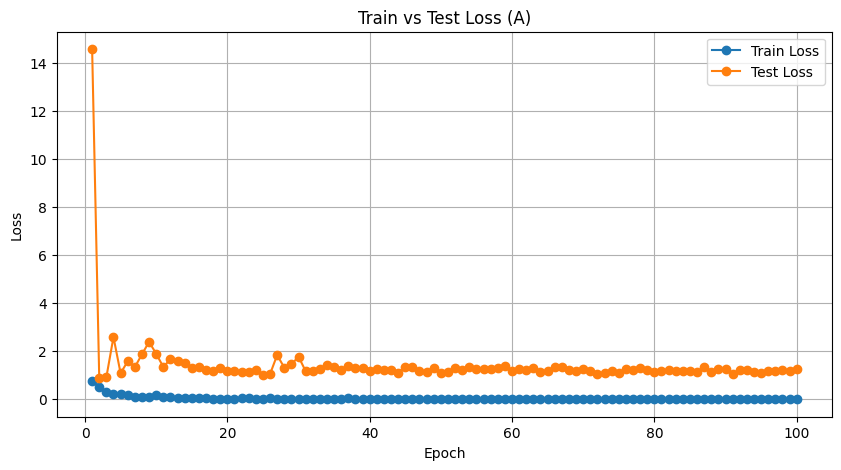


=== Experiment B ===


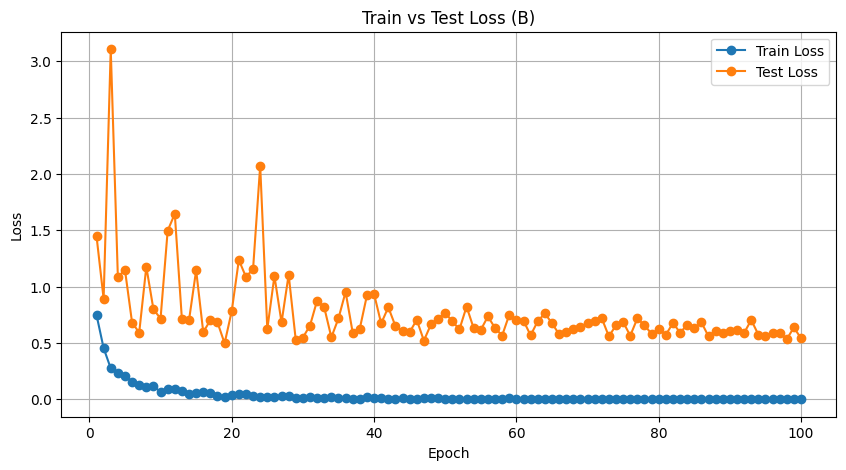


=== Experiment C ===


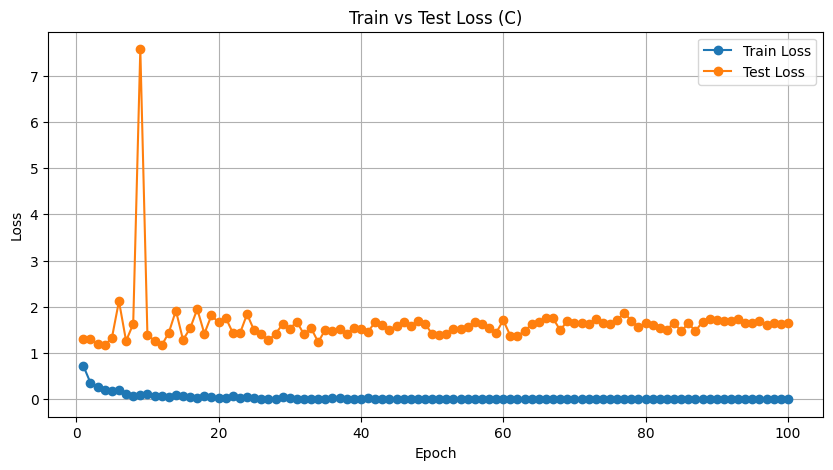

In [48]:
for xp in dfs:
    print(f"\n=== Experiment {xp} ===")
    train_pivot = dfs[xp]['train_pivot']
    val_pivot = dfs[xp]['val_pivot']
    plot_metrics(train_pivot, val_pivot, 'metrics.LOSS', 'metrics.LOSS', 'Train Loss', 'Test Loss', 'Loss', f'Train vs Test Loss ({xp})')



=== Experiment A ===


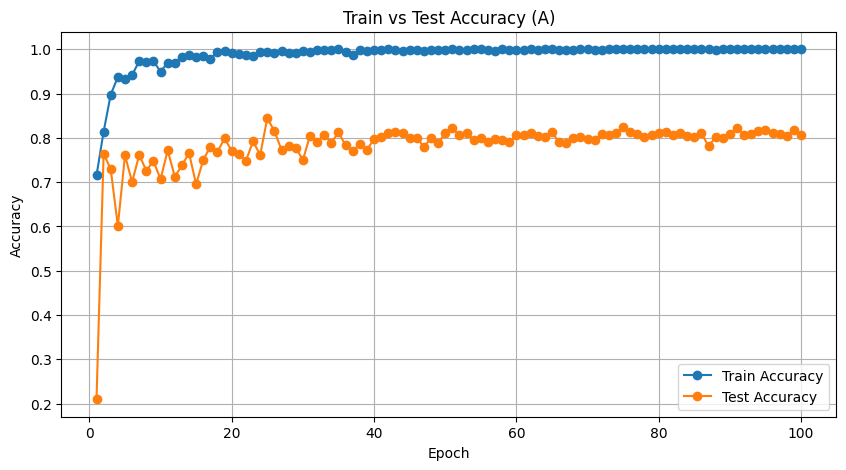


=== Experiment B ===


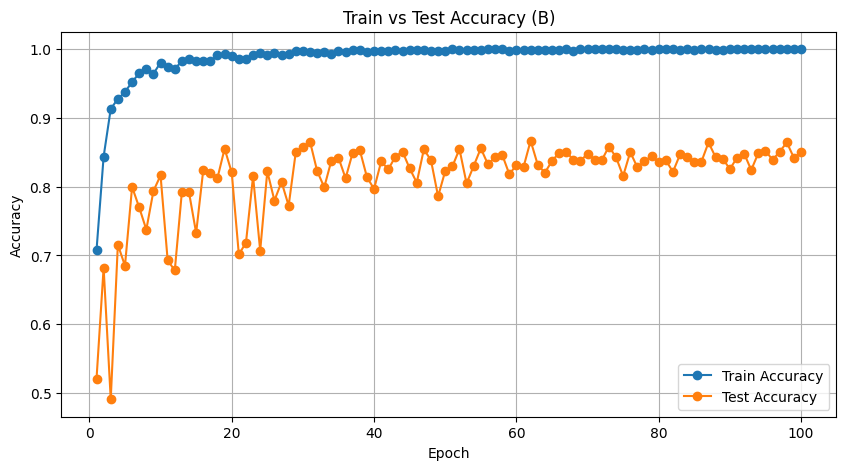


=== Experiment C ===


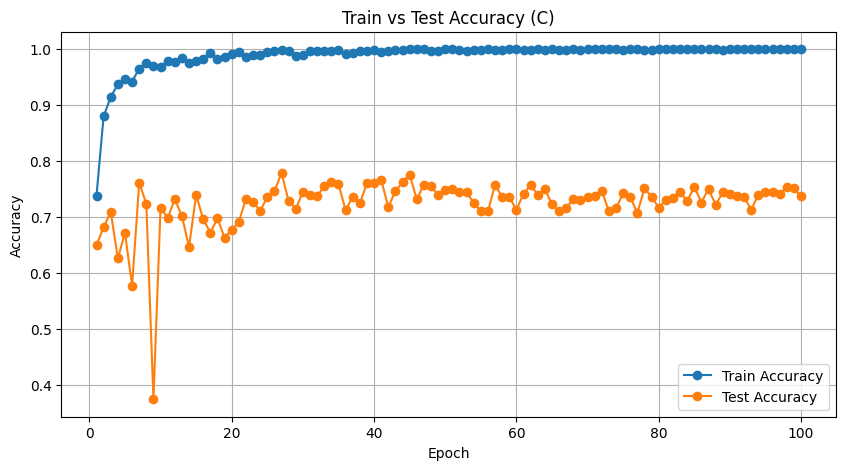

In [49]:
for xp in dfs:
    print(f"\n=== Experiment {xp} ===")
    train_pivot = dfs[xp]['train_pivot']
    val_pivot = dfs[xp]['val_pivot']
    plot_metrics(train_pivot, val_pivot, 'metrics.TRAIN_ACC', 'metrics.TEST_ACC', 'Train Accuracy', 'Test Accuracy', 'Accuracy', f'Train vs Test Accuracy ({xp})')



=== Experiment A ===


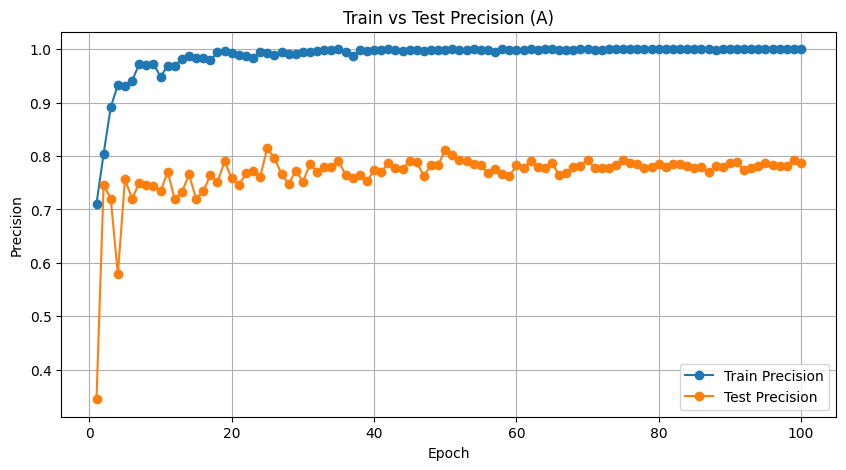


=== Experiment B ===


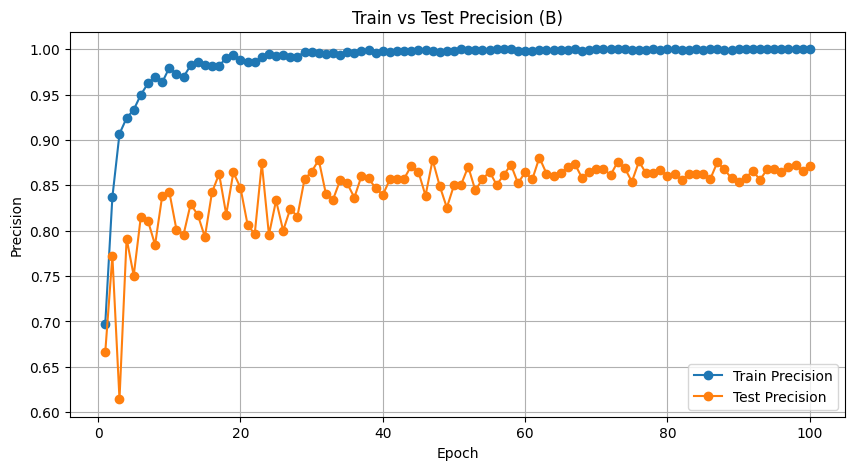


=== Experiment C ===


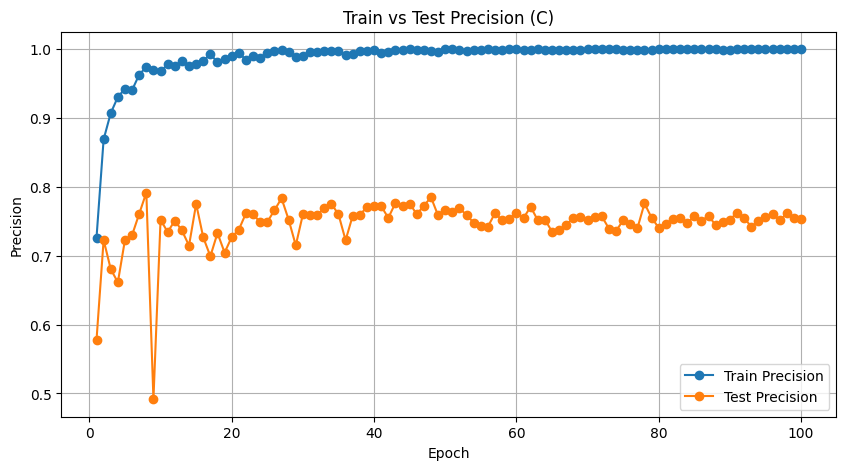

In [50]:
for xp in dfs:
    print(f"\n=== Experiment {xp} ===")
    train_pivot = dfs[xp]['train_pivot']
    val_pivot = dfs[xp]['val_pivot']
    plot_metrics(train_pivot, val_pivot, 'metrics.TRAIN_PREC', 'metrics.TEST_PREC', 'Train Precision', 'Test Precision', 'Precision', f'Train vs Test Precision ({xp})')



=== Experiment A ===


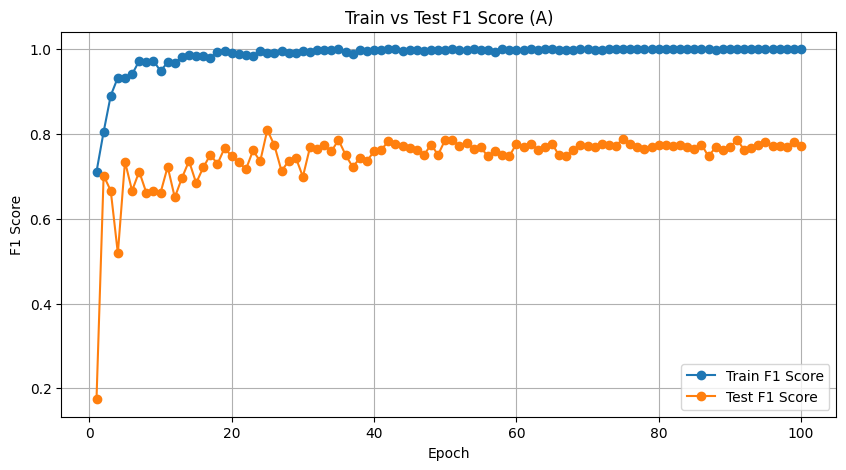


=== Experiment B ===


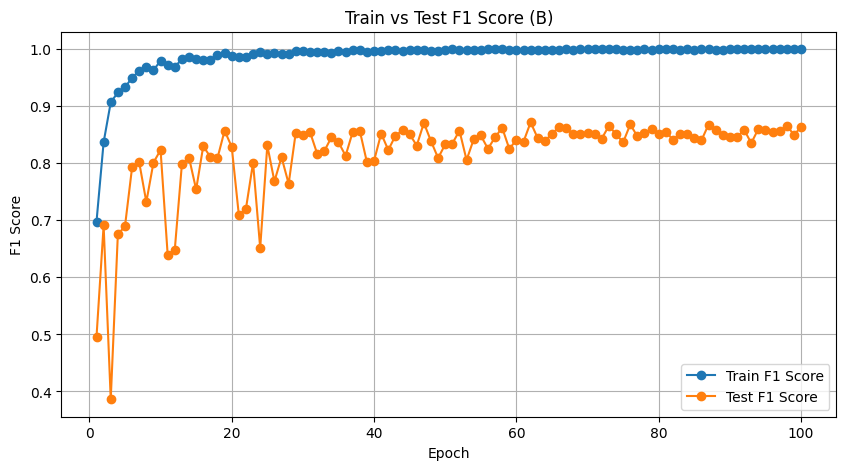


=== Experiment C ===


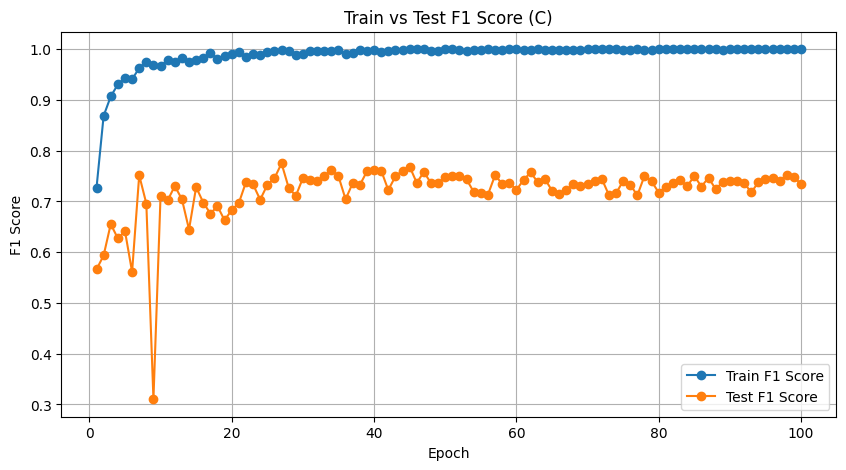

In [51]:
for xp in dfs:
    print(f"\n=== Experiment {xp} ===")
    train_pivot = dfs[xp]['train_pivot']
    val_pivot = dfs[xp]['val_pivot']
    plot_metrics(train_pivot, val_pivot, 'metrics.TRAIN_F1', 'metrics.TEST_F1', 'Train F1 Score', 'Test F1 Score', 'F1 Score', f'Train vs Test F1 Score ({xp})')


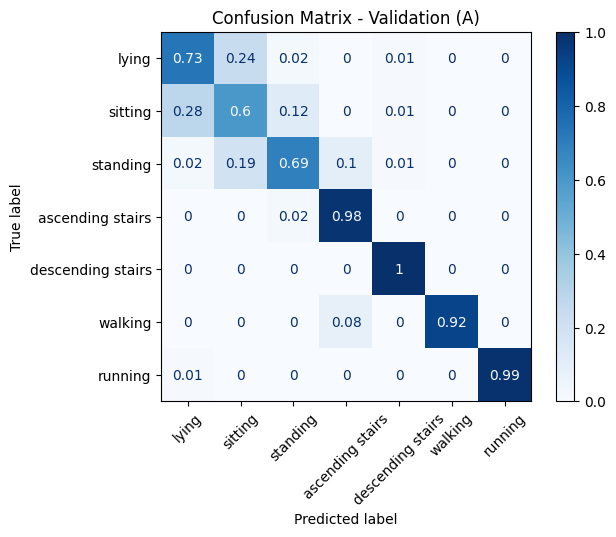

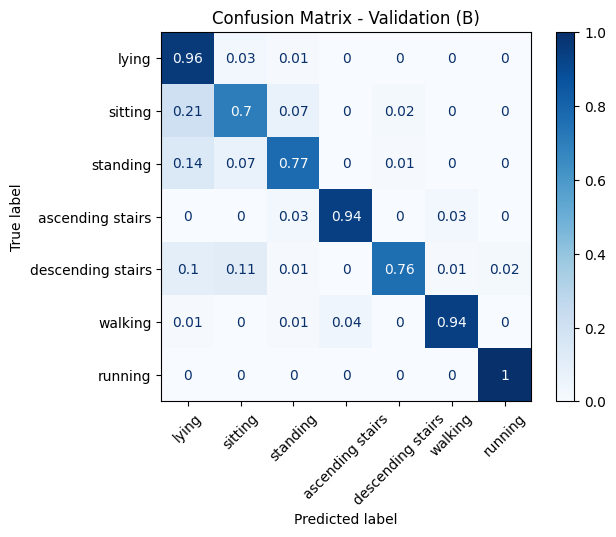

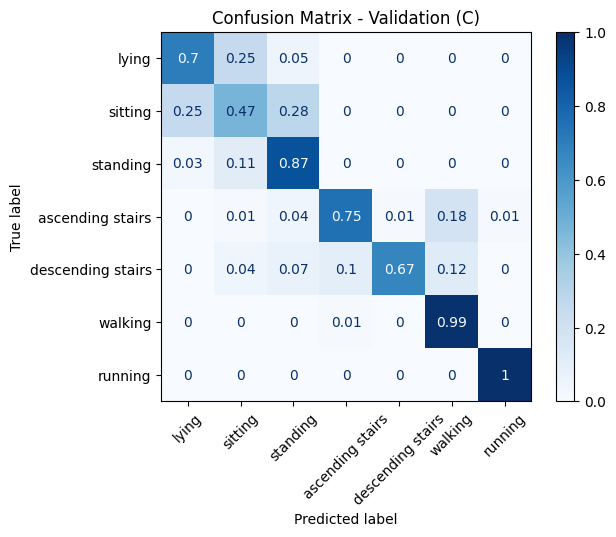

In [52]:
for xp in dfs:
    val_pivot = dfs[xp]['val_pivot']
    max_index = val_pivot['metrics.TEST_ACC'].idxmax()
    
    if 'metrics.TEST_CONF' in val_pivot.columns:
        conf_matrix_str = val_pivot['metrics.TEST_CONF'][max_index]
        
        if isinstance(conf_matrix_str, str):
            numbers_only = re.sub(r'[\[\]]', '', conf_matrix_str)
            flat = np.fromstring(numbers_only, sep=' ')
            size = int(np.sqrt(len(flat)))
            conf_matrix = flat.reshape((size, size))
        else:
            conf_matrix = np.array(conf_matrix_str, dtype=float)
        
        disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix.round(2), display_labels=mapping)
        disp.plot(cmap='Blues')
        plt.title(f'Confusion Matrix - Validation ({xp})')
        plt.xticks(rotation=45)
        plt.show()


In [53]:
# Collect metrics for averaging
acc_list = []
prec_list = []
f1_list = []

for xp in dfs:
    val_pivot = dfs[xp]['val_pivot']
    max_index = val_pivot['metrics.TEST_ACC'].idxmax()
    
    acc = val_pivot['metrics.TEST_ACC'][max_index]
    prec = val_pivot['metrics.TEST_PREC'][max_index]
    f1 = val_pivot['metrics.TEST_F1'][max_index]
    
    acc_list.append(acc)
    prec_list.append(prec)
    f1_list.append(f1)
    
    print(f"\n=== Best Epoch for Experiment {xp} ===")
    print(f"Balanced Accuracy: {acc}")
    print(f"Precision: {prec}")
    print(f"F1 Score: {f1}")

# Print averages
print("\n=== Average Across Experiments ===")
print(f"Average Balanced Accuracy: {sum(acc_list) / len(acc_list):.4f}")
print(f"Average Precision: {sum(prec_list) / len(prec_list):.4f}")
print(f"Average F1 Score: {sum(f1_list) / len(f1_list):.4f}")



=== Best Epoch for Experiment A ===
Balanced Accuracy: 0.8443544726512212
Precision: 0.8154236001309239
F1 Score: 0.8095935040088822

=== Best Epoch for Experiment B ===
Balanced Accuracy: 0.8668630189435147
Precision: 0.8806461834339949
F1 Score: 0.8717967129069495

=== Best Epoch for Experiment C ===
Balanced Accuracy: 0.7784370278648619
Precision: 0.7835154078388656
F1 Score: 0.774985904805081

=== Average Across Experiments ===
Average Balanced Accuracy: 0.8299
Average Precision: 0.8265
Average F1 Score: 0.8188


In [54]:
output_file = f"{csv_path}.txt"

with open(output_file, "w") as f:
    f.write("=== Experiment Parameters ===\n")
    
    # Split csv_path into parts and write them
    parts = csv_path.split("_")
    for part in parts:
        # If part contains a number after a name, add space between
        match = re.match(r"([a-zA-Z]+)([0-9\.\-eE]+)", part)
        if match:
            name, value = match.groups()
            f.write(f"{name} {value}\n")
        else:
            f.write(f"{part}\n")
    
    f.write("\n=== Best Epoch Results per Experiment ===\n")
    
    acc_list = []
    prec_list = []
    f1_list = []
    
    for xp in dfs:
        val_pivot = dfs[xp]['val_pivot']
        max_index = val_pivot['metrics.TEST_ACC'].idxmax()
        
        acc = val_pivot['metrics.TEST_ACC'][max_index]
        prec = val_pivot['metrics.TEST_PREC'][max_index]
        f1_ = val_pivot['metrics.TEST_F1'][max_index]
        
        acc_list.append(acc)
        prec_list.append(prec)
        f1_list.append(f1_)
        
        f.write(f"\nExperiment {xp}:\n")
        f.write(f"Balanced Accuracy: {acc}\n")
        f.write(f"Precision: {prec}\n")
        f.write(f"F1 Score: {f1_}\n")
    
    f.write("\n=== Average Across Experiments ===\n")
    f.write(f"Average Balanced Accuracy: {sum(acc_list) / len(acc_list):.4f}\n")
    f.write(f"Average Precision: {sum(prec_list) / len(prec_list):.4f}\n")
    f.write(f"Average F1 Score: {sum(f1_list) / len(f1_list):.4f}\n")

print(f"Results saved to {output_file}")


Results saved to exp_lr4.7e-3_step6_gamma0.808_epochs100_cls7_ch6_win1024_stride256_bs32_wd6.7e-5_019.txt
